<a href="https://colab.research.google.com/github/a2w3r4/ML-for-High-Energy-Physics-/blob/main/ML_for_High_ENERGY_Physics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
import torch
import torch.utils.data as data
from torch.utils.data.sampler import SubsetRandomSampler
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.autograd import Variable
import numpy as np

In [29]:
import torchvision.datasets as datasets


# Load training set
train_dataset = datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=None
)

# Load test set
test_dataset = datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=None
)

In [ ]:
from torchvision import datasets, transforms

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
transform=transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.0,), (1.0,))
        ])

dataset = datasets.MNIST('./data', train=True, download=False, transform=transform)

In [ ]:
if(torch.backends.cuda.is_built()):
  device='cude'
elif(torch.backends.mps.is_built()):
  device='mps'
else:
  device='cpu'


In [ ]:
X,y = dataset[12]

In [ ]:
torch.argwhere

<function torch._VariableFunctionsClass.argwhere>

In [ ]:
torch.argwhere??

In [ ]:
img_array = X[0]
torch.argwhere(img_array > 0.)[:,0]/img_array.shape[0]

tensor([0.1786, 0.1786, 0.1786, 0.1786, 0.1786, 0.1786, 0.1786, 0.1786, 0.1786,
        0.1786, 0.1786, 0.1786, 0.1786, 0.2143, 0.2143, 0.2143, 0.2143, 0.2143,
        0.2143, 0.2143, 0.2143, 0.2143, 0.2143, 0.2143, 0.2143, 0.2143, 0.2143,
        0.2143, 0.2143, 0.2500, 0.2500, 0.2500, 0.2500, 0.2500, 0.2500, 0.2500,
        0.2500, 0.2500, 0.2500, 0.2500, 0.2500, 0.2500, 0.2500, 0.2500, 0.2500,
        0.2857, 0.2857, 0.2857, 0.2857, 0.2857, 0.2857, 0.2857, 0.2857, 0.2857,
        0.2857, 0.3214, 0.3214, 0.3214, 0.3214, 0.3214, 0.3571, 0.3571, 0.3571,
        0.3571, 0.3571, 0.3571, 0.3929, 0.3929, 0.3929, 0.3929, 0.3929, 0.3929,
        0.3929, 0.4286, 0.4286, 0.4286, 0.4286, 0.4286, 0.4286, 0.4286, 0.4286,
        0.4643, 0.4643, 0.4643, 0.4643, 0.4643, 0.4643, 0.4643, 0.4643, 0.4643,
        0.4643, 0.5000, 0.5000, 0.5000, 0.5000, 0.5000, 0.5000, 0.5000, 0.5000,
        0.5000, 0.5000, 0.5000, 0.5000, 0.5357, 0.5357, 0.5357, 0.5357, 0.5357,
        0.5357, 0.5357, 0.5357, 0.5357, 

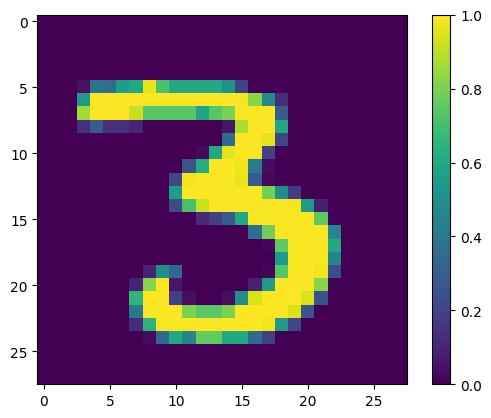

In [ ]:
plt.imshow(X[0].numpy())
plt.colorbar()

In [ ]:
# def transform_2d_image_to_point_cloud(data):

# img, label = data
# img_array = img[0]
# values = img_array[img_array > 0]
# x_coord = torch.argwhere(img_array > 0.)[:,0]/img_array.shape[0]
# y_coord = torch.argwhere(img_array > 0.)[:,1]/img_array.shape[0]

# return torch.stack( (x_coord, y_coord, values), dim = -1), label

In [ ]:
# vect = transform_2d_image_to_point_cloudT(X)

In [ ]:
class MNISTPC_Dataset(data.Dataset):

  def __init__(self, dataset_path:str, train:bool = True, download:bool = False, mean:float = 0., std:float = 1.) -> None:

    """
    Inputs:
         size - Number of data-points we want to generate
         std - Standard deviation of the noise
    """

    super().__init__()

    self.transform = transforms.Compose(
        [
            transforms.ToTensor(),
            transforms.Normalize((mean,), (std,))
        ]
    )

    # Fixed typo: changed 'trranform' to 'transform'
    self.pc_dataset = MNIST(dataset_path, train=train, download=download, transform=self.transform)
    self.pc_dataset = [self.transform_2d_image_to_point_cloud(self.pc_dataset[idx]) for idx in range(len(self.pc_dataset))]

  def transform_2d_image_to_point_cloud(self, data_i:tuple)  -> dict :
      img, label = data_i
      img_array = img[0]
      values = img_array[img_array > 0]
      x_coord = torch.argwhere(img_array > 0.)[:,0]/img_array.shape[0]
      y_coord = torch.argwhere(img_array > 0.)[:,1]/img_array.shape[0]

      point_vec = torch.stack( (x_coord, y_coord, values), dim=-1)

      return {'point' : point_vec, 'label' : label, 'seq_length' : len(point_vec)}

  def __len__(self) -> int:
    return len(self.pc_dataset)

  def __getitem__(self, idx:int)  -> dict :
    return self.pc_dataset[idx]

In [ ]:
pip install torch_geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 23.9 MB/s eta 0:00:00


In [ ]:
pip install torch_scatter torch_sparse torch_cluster torch_spline_conv -f https://data.pyg.org/whl/torch-$(python -c "import torch; print(torch.__version__)").html

Looking in links: https://data.pyg.org/whl/torch-2.11.0+cpu.html
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.1/682.1 kB 8.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 30.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 828.0/828.0 kB 2.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for torch_spline_conv: filename=torch_spline_conv-1.2.2-cp313-cp313-linux_x86_64.whl size=315999 sha256=55de443bbc96c986e1259edfded04cb16c943b930e5573d15efa68508367fdd4
  Stored in directory: /root/.cache/pip/wheels/e8/f6/19/afe8f95c2f609be96edf7b232ef4e100076d661c74d1c92332
Successfully built torch_spline_conv


In [ ]:
import torchvision.transforms as torchvision_T
import torch_geometric.transforms as PyG_T
from torchvision.datasets import MNIST

# 1. Standard torchvision MNIST dataset
torchvision_mnist = MNIST(
    root='./data/',
    train=True,
    download=True,
    transform=torchvision_T.ToTensor()
)

# 2. Convert a standard image sample into a PyG graph / point cloud
sample_img, label = torchvision_mnist[0]

# Sample 1024 points from non-zero pixels
sample_points_transform = PyG_T.SamplePoints(num=1024)
# Or use GridSampling / ToSLIC to turn 2D pixel grids into PyG graph objects

In [ ]:
import torchvision.transforms as torchvision_T
from torchvision.datasets import MNIST

# Fix: transform=torchvision_T.ToTensor() (spelled with one 'r')
torchvision_mnist = MNIST(
    root='./data/',
    train=True,
    download=True,
    transform=torchvision_T.ToTensor()
)

In [ ]:
from torch_geometric.datasets import MNISTSuperpixels

# Downloads and loads pre-constructed graph/point-cloud dataset
pc_dataset = MNISTSuperpixels(root='./data/MNISTSuperpixels', train=True)

# Inspect sample
print(pc_dataset[0])
# Output: Data(x=[75, 1], edge_index=[2, 1396], y=[1], pos=[75, 2])

Extracting data/MNISTSuperpixels/raw/MNISTSuperpixels.zip
Processing...
Done!


Data(x=[75, 1], edge_index=[2, 1399], y=[1], pos=[75, 2])


In [20]:
import torch_geometric.transforms as T
from torch_geometric.datasets import MNISTSuperpixels

# Download and load 2D point cloud / graph representation of MNIST (removing download=True)
pc_dataset = MNISTSuperpixels(root='./data/', train=True, transform=T.SamplePoints(num=1024))

Extracting data/raw/MNISTSuperpixels.zip
Processing...
Done!


In [21]:
pc_dataset = MNISTPC_Dataset('./data/')

In [22]:
pc_dataset[19]

{'point': tensor([[0.2500, 0.4643, 0.0706],
         [0.2500, 0.5000, 0.4118],
         [0.2500, 0.5357, 0.8902],
         [0.2500, 0.5714, 0.9922],
         [0.2500, 0.6071, 0.9922],
         [0.2500, 0.6429, 0.4784],
         [0.2857, 0.4286, 0.2235],
         [0.2857, 0.4643, 0.7804],
         [0.2857, 0.5000, 0.9922],
         [0.2857, 0.5357, 0.9882],
         [0.2857, 0.5714, 0.9882],
         [0.2857, 0.6071, 0.9882],
         [0.2857, 0.6429, 0.9882],
         [0.2857, 0.6786, 0.6235],
         [0.3214, 0.3929, 0.0784],
         [0.3214, 0.4286, 0.8275],
         [0.3214, 0.4643, 0.9882],
         [0.3214, 0.5000, 0.9098],
         [0.3214, 0.5357, 0.5961],
         [0.3214, 0.5714, 0.2863],
         [0.3214, 0.6071, 0.6549],
         [0.3214, 0.6429, 0.9882],
         [0.3214, 0.6786, 0.8431],
         [0.3214, 0.7143, 0.0235],
         [0.3571, 0.3929, 0.7725],
         [0.3571, 0.4286, 0.9882],
         [0.3571, 0.4643, 0.7137],
         [0.3571, 0.6071, 0.1451],
         [0

In [23]:
def visualize_samples(data, label, marker='0'):
    if isinstance(data, torch.Tensor):
      data = data.cpu().numpy()
    if isinstance(label, torch.Tensor):
      label = label.cpu().numpy()

    plt.figure(figsize=(4.4))
    plt.scatter(data[:,0], data[:,1], edgecolor="#333", marker=marker, label="Class" + str(label),)

    plt.title("Dataset samples")
    plt.ylabel(r"$x_2$")
    plt.xlabel(r"$x_1$")
    plt.legend()
    plt.show()





In [24]:
import matplotlib.pyplot as plt
import torch

def visualize_samples(data, label, marker='o'):
    if isinstance(data, torch.Tensor):
        data = data.cpu().numpy()
    if isinstance(label, torch.Tensor):
        label = label.cpu().numpy()

    # Fix: Use a 2-element tuple (width, height) instead of float 4.4
    plt.figure(figsize=(4, 4))

    plt.scatter(
        data[:, 0],
        data[:, 1],
        edgecolor="#333",
        marker=marker,
        label="Class " + str(label)
    )

    plt.title("Dataset samples")
    plt.ylabel(r"$x_2$")
    plt.xlabel(r"$x_1$")
    plt.legend()
    plt.show()

In [25]:
pc, label = pc_dataset[19]['point'], pc_dataset[19]['label']

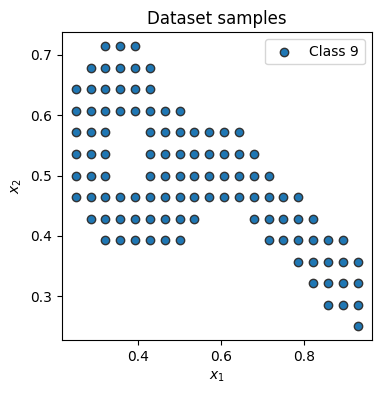

In [26]:
visualize_samples(pc, label)

In [34]:
def create_batch(data_list : list) -> tuple:

  max_length = np.max([data_list[idx]['seq_length'] for idx in range(len(data_list))  ])

  pc_list, label_list = [], []

  for idx in range(len(data_list)) :


        pc, label = data_list[idx]['point'], data_list[idx]['label']

        N, C = pc.shape[0], pc.shape[1]

        pc_padded = torch.zeros([1, max_length, C])

        pc = pc.reshape(1, N, C) # (N, C) -> (1, N, C)

        pc_padded[:, 0 : N, :   ] = pc[:,:,:] #

        pc_list.append(pc_padded)
        label_list.append( torch.tensor([label]) )

  return torch.cat(pc_list, dim=0), torch.cat(label_list, dim=0)

In [35]:
type(pc_dataset)

__main__.MNISTPC_Dataset

In [39]:
pc_dataloader = data.DataLoader(dataset=pc_dataset, batch_size=5, shuffle=True, collate_fn=create_batch)

In [40]:
pc_chunk, label_chunk = next(iter(pc_dataloader))

In [41]:
pc_chunk.shape, label_chunk.shape

(torch.Size([5, 197, 3]), torch.Size([5]))

# Define the basic deepest layer

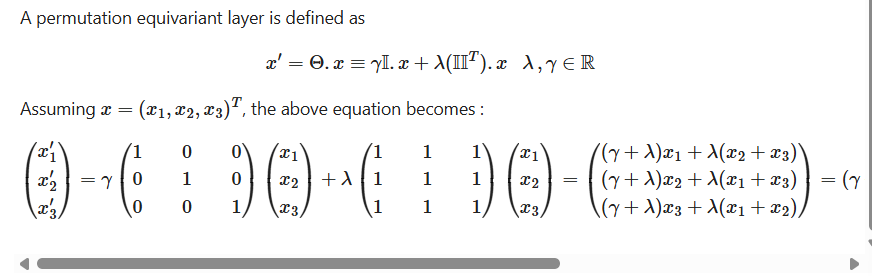

<math xmlns="http://www.w3.org/1998/Math/MathML" display="block">
  <mrow data-mjx-texclass="INNER">
    <mo data-mjx-texclass="OPEN">(</mo>
    <mtable columnspacing="1em" rowspacing="4pt">
      <mtr>
        <mtd>
          <msubsup>
            <mi>x</mi>
            <mn>1</mn>
            <mo data-mjx-alternate="1">&#x2032;</mo>
          </msubsup>
        </mtd>
      </mtr>
      <mtr>
        <mtd>
          <msubsup>
            <mi>x</mi>
            <mn>2</mn>
            <mo data-mjx-alternate="1">&#x2032;</mo>
          </msubsup>
        </mtd>
      </mtr>
      <mtr>
        <mtd>
          <msubsup>
            <mi>x</mi>
            <mn>3</mn>
            <mo data-mjx-alternate="1">&#x2032;</mo>
          </msubsup>
        </mtd>
      </mtr>
    </mtable>
    <mo data-mjx-texclass="CLOSE">)</mo>
  </mrow>
  <mo>=</mo>
  <mi>&#x3B3;</mi>
  <mrow data-mjx-texclass="INNER">
    <mo data-mjx-texclass="OPEN">(</mo>
    <mtable columnspacing="1em" rowspacing="4pt">
      <mtr>
        <mtd>
          <mn>1</mn>
        </mtd>
        <mtd></mtd>
        <mtd>
          <mn>0</mn>
        </mtd>
        <mtd></mtd>
        <mtd>
          <mn>0</mn>
        </mtd>
      </mtr>
      <mtr>
        <mtd>
          <mn>0</mn>
        </mtd>
        <mtd></mtd>
        <mtd>
          <mn>1</mn>
        </mtd>
        <mtd></mtd>
        <mtd>
          <mn>0</mn>
        </mtd>
      </mtr>
      <mtr>
        <mtd>
          <mn>0</mn>
        </mtd>
        <mtd></mtd>
        <mtd>
          <mn>0</mn>
        </mtd>
        <mtd></mtd>
        <mtd>
          <mn>1</mn>
        </mtd>
      </mtr>
    </mtable>
    <mo data-mjx-texclass="CLOSE">)</mo>
  </mrow>
  <mrow data-mjx-texclass="INNER">
    <mo data-mjx-texclass="OPEN">(</mo>
    <mtable columnspacing="1em" rowspacing="4pt">
      <mtr>
        <mtd>
          <msub>
            <mi>x</mi>
            <mn>1</mn>
          </msub>
        </mtd>
      </mtr>
      <mtr>
        <mtd>
          <msub>
            <mi>x</mi>
            <mn>2</mn>
          </msub>
        </mtd>
      </mtr>
      <mtr>
        <mtd>
          <msub>
            <mi>x</mi>
            <mn>3</mn>
          </msub>
        </mtd>
      </mtr>
    </mtable>
    <mo data-mjx-texclass="CLOSE">)</mo>
  </mrow>
  <mo>+</mo>
  <mi>&#x3BB;</mi>
  <mrow data-mjx-texclass="INNER">
    <mo data-mjx-texclass="OPEN">(</mo>
    <mtable columnspacing="1em" rowspacing="4pt">
      <mtr>
        <mtd>
          <mn>1</mn>
        </mtd>
        <mtd></mtd>
        <mtd>
          <mn>1</mn>
        </mtd>
        <mtd></mtd>
        <mtd>
          <mn>1</mn>
        </mtd>
      </mtr>
      <mtr>
        <mtd>
          <mn>1</mn>
        </mtd>
        <mtd></mtd>
        <mtd>
          <mn>1</mn>
        </mtd>
        <mtd></mtd>
        <mtd>
          <mn>1</mn>
        </mtd>
      </mtr>
      <mtr>
        <mtd>
          <mn>1</mn>
        </mtd>
        <mtd></mtd>
        <mtd>
          <mn>1</mn>
        </mtd>
        <mtd></mtd>
        <mtd>
          <mn>1</mn>
        </mtd>
      </mtr>
    </mtable>
    <mo data-mjx-texclass="CLOSE">)</mo>
  </mrow>
  <mrow data-mjx-texclass="INNER">
    <mo data-mjx-texclass="OPEN">(</mo>
    <mtable columnspacing="1em" rowspacing="4pt">
      <mtr>
        <mtd>
          <msub>
            <mi>x</mi>
            <mn>1</mn>
          </msub>
        </mtd>
      </mtr>
      <mtr>
        <mtd>
          <msub>
            <mi>x</mi>
            <mn>2</mn>
          </msub>
        </mtd>
      </mtr>
      <mtr>
        <mtd>
          <msub>
            <mi>x</mi>
            <mn>3</mn>
          </msub>
        </mtd>
      </mtr>
    </mtable>
    <mo data-mjx-texclass="CLOSE">)</mo>
  </mrow>
  <mspace linebreak="newline"></mspace>
  <mspace linebreak="newline"></mspace>
  <mo>=</mo>
  <mrow data-mjx-texclass="INNER">
    <mo data-mjx-texclass="OPEN">(</mo>
    <mtable columnspacing="1em" rowspacing="4pt">
      <mtr>
        <mtd>
          <mo stretchy="false">(</mo>
          <mi>&#x3B3;</mi>
          <mo>+</mo>
          <mi>&#x3BB;</mi>
          <mo stretchy="false">)</mo>
          <msub>
            <mi>x</mi>
            <mn>1</mn>
          </msub>
          <mo>+</mo>
          <mi>&#x3BB;</mi>
          <mo stretchy="false">(</mo>
          <msub>
            <mi>x</mi>
            <mn>2</mn>
          </msub>
          <mo>+</mo>
          <msub>
            <mi>x</mi>
            <mn>3</mn>
          </msub>
          <mo stretchy="false">)</mo>
        </mtd>
      </mtr>
      <mtr>
        <mtd>
          <mo stretchy="false">(</mo>
          <mi>&#x3B3;</mi>
          <mo>+</mo>
          <mi>&#x3BB;</mi>
          <mo stretchy="false">)</mo>
          <msub>
            <mi>x</mi>
            <mn>2</mn>
          </msub>
          <mo>+</mo>
          <mi>&#x3BB;</mi>
          <mo stretchy="false">(</mo>
          <msub>
            <mi>x</mi>
            <mn>1</mn>
          </msub>
          <mo>+</mo>
          <msub>
            <mi>x</mi>
            <mn>3</mn>
          </msub>
          <mo stretchy="false">)</mo>
        </mtd>
      </mtr>
      <mtr>
        <mtd>
          <mo stretchy="false">(</mo>
          <mi>&#x3B3;</mi>
          <mo>+</mo>
          <mi>&#x3BB;</mi>
          <mo stretchy="false">)</mo>
          <msub>
            <mi>x</mi>
            <mn>3</mn>
          </msub>
          <mo>+</mo>
          <mi>&#x3BB;</mi>
          <mo stretchy="false">(</mo>
          <msub>
            <mi>x</mi>
            <mn>1</mn>
          </msub>
          <mo>+</mo>
          <msub>
            <mi>x</mi>
            <mn>2</mn>
          </msub>
          <mo stretchy="false">)</mo>
        </mtd>
      </mtr>
    </mtable>
    <mo data-mjx-texclass="CLOSE">)</mo>
  </mrow>
  <mspace linebreak="newline"></mspace>
  <mspace linebreak="newline"></mspace>
  <mo>=</mo>
  <mo stretchy="false">(</mo>
  <mi>&#x3B3;</mi>
  <mo>+</mo>
  <mi>&#x3BB;</mi>
  <mo stretchy="false">)</mo>
  <mrow data-mjx-texclass="INNER">
    <mo data-mjx-texclass="OPEN">(</mo>
    <mtable columnspacing="1em" rowspacing="4pt">
      <mtr>
        <mtd>
          <msub>
            <mi>x</mi>
            <mn>1</mn>
          </msub>
        </mtd>
      </mtr>
      <mtr>
        <mtd>
          <msub>
            <mi>x</mi>
            <mn>2</mn>
          </msub>
        </mtd>
      </mtr>
      <mtr>
        <mtd>
          <msub>
            <mi>x</mi>
            <mn>3</mn>
          </msub>
        </mtd>
      </mtr>
    </mtable>
    <mo data-mjx-texclass="CLOSE">)</mo>
  </mrow>
  <mo>&#x2212;</mo>
  <mi>&#x3BB;</mi>
  <mrow data-mjx-texclass="INNER">
    <mo data-mjx-texclass="OPEN">(</mo>
    <mtable columnspacing="1em" rowspacing="4pt">
      <mtr>
        <mtd>
          <msub>
            <mi>x</mi>
            <mn>1</mn>
          </msub>
          <mo>&#x2212;</mo>
          <mo data-mjx-texclass="OP">&#x2211;</mo>
          <msub>
            <mi>x</mi>
            <mi>i</mi>
          </msub>
        </mtd>
      </mtr>
      <mtr>
        <mtd>
          <msub>
            <mi>x</mi>
            <mn>2</mn>
          </msub>
          <mo>&#x2212;</mo>
          <mo data-mjx-texclass="OP">&#x2211;</mo>
          <msub>
            <mi>x</mi>
            <mi>i</mi>
          </msub>
        </mtd>
      </mtr>
      <mtr>
        <mtd>
          <msub>
            <mi>x</mi>
            <mn>3</mn>
          </msub>
          <mo>&#x2212;</mo>
          <mo data-mjx-texclass="OP">&#x2211;</mo>
          <msub>
            <mi>x</mi>
            <mi>i</mi>
          </msub>
        </mtd>
      </mtr>
    </mtable>
    <mo data-mjx-texclass="CLOSE">)</mo>
  </mrow>
  <mo>=</mo>
  <mi mathvariant="normal">&#x393;</mi>
  <mo>.</mo>
  <mi>x</mi>
  <mo>+</mo>
  <mi mathvariant="normal">&#x39B;</mi>
  <mo>.</mo>
  <mrow data-mjx-texclass="ORD">
    <mo minsize="1.623em" maxsize="1.623em">(</mo>
  </mrow>
  <mi>x</mi>
  <mo>&#x2212;</mo>
  <mi>&#x3B1;</mi>
  <mo stretchy="false">(</mo>
  <mi>x</mi>
  <mo stretchy="false">)</mo>
  <mrow data-mjx-texclass="ORD">
    <mo minsize="1.623em" maxsize="1.623em">)</mo>
  </mrow>
</math>

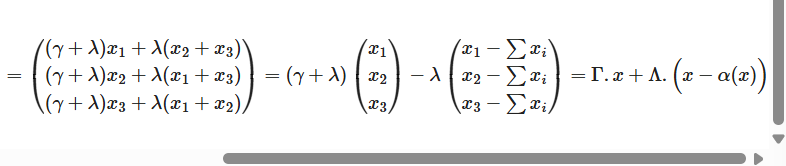

In [42]:
class DeepSetLayer(nn.Module):
    def __init__(self, in_features:int, out_features:int,  normalization:str = '', pool:str = 'mean') -> None :
        """
        DeepSets single layer
        :param in_features: input's number of features
        :param out_features: output's number of features
        :param attention: Whether to use attention
        :param normalization: normalization method - 'fro' or 'batchnorm'

        """
        super(DeepSetLayer, self).__init__()

        self.Gamma = nn.Linear(in_features, out_features)
        self.Lambda = nn.Linear(in_features, out_features)

        self.normalization = normalization
        self.pool = pool

        if normalization == 'batchnorm':
            self.bn = nn.BatchNorm1d(out_features)

    def forward(self, x : torch.Tensor) -> torch.Tensor :
        # x.shape = (B, N, C)
        if(self.pool == 'mean') :
            x = self.Gamma(x) + self.Lambda(x - x.mean(dim=1, keepdim=True)) # -- the average is over the points -- #
        elif(self.pool == 'max') :
            x = self.Gamma(x) + self.Lambda(x - x.max(dim=1, keepdim=True)) # -- the max is over the points -- #

        # normalization
        if self.normalization == 'batchnorm':
            x = self.bn(x)


        return x

In [43]:
ds_layer = DeepSetLayer(in_features = 3, out_features = 4)

In [45]:
y = ds_layer(pc_chunk)

In [46]:
pc_chunk.shape, y.shape

(torch.Size([5, 197, 3]), torch.Size([5, 197, 4]))

# Make the full deepest model as stack of Deepset Layers and non-linear activation functions

In [47]:
class DeepSet(nn.Module):
    def __init__(self, in_features:int, feats:list, n_class:int, normalization:str = '', pool:str = 'mean') ->None:
        """
        DeepSets implementation
        :param in_features: input's number of features
        :param feats: list of features for each deepsets layer
        """
        super(DeepSet, self).__init__()

        layers = []

        layers.append(DeepSetLayer(in_features = in_features, out_features = feats[0], normalization = normalization, pool = pool))
        for i in range(1, len(feats)):
            layers.append(nn.ReLU())
            layers.append(DeepSetLayer(in_features = feats[i-1], out_features = feats[i], normalization = normalization, pool = pool))

        layers.append(DeepSetLayer(in_features = feats[-1], out_features = n_class, normalization = normalization, pool = pool))
        #self.sequential = nn.Sequential(*layers)
        self.sequential = nn.ModuleList(layers)

    def forward(self, x:torch.Tensor) -> torch.Tensor:
        #return self.sequential(x)
        for i, layer in enumerate(self.sequential):
            x = layer(x)

        x = x.mean(dim=1) # -- average over the points -- #
        out = F.log_softmax(x, dim=-1)

        return out

In [48]:
model  = DeepSet(in_features=3, feats=[5,9, 12, 16, 13], n_class=10)
model = model.to(device)

In [49]:
y = model(pc_chunk.to(device))

In [50]:
y.shape, label_chunk.shape

(torch.Size([5, 10]), torch.Size([5]))

In [51]:
F.nll_loss(input=y, target=label_chunk.to(device))

tensor(2.3389, grad_fn=<NllLossBackward0>)

In [52]:
torch.backends.mps.is_built()

False

In [53]:
device

'cpu'

# creating the training block

In [54]:
def train(model, device, train_loader, optimizer):

    train_loss_ep = 0.

    model.train()
    for batch_idx, (data, target) in enumerate(train_loader):
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = F.nll_loss(output, target)
        loss.backward()
        optimizer.step()

        train_loss_ep += loss.item() * data.size(0)

    return train_loss_ep

# creating the testing block

In [55]:
def test(model, device, test_loader):

    test_loss_ep = 0.

    model.eval()
    for batch_idx, (data, target) in enumerate(test_loader):
        data, target = data.to(device), target.to(device)

        output = model(data)
        loss = F.nll_loss(output, target)

        test_loss_ep += loss.item() * data.size(0)

    return test_loss_ep

# Let's prepare the fulldataset and dataloaders

In [56]:
# number of subprocesses to use for data loading
num_workers = 0
# how many samples per batch to load
batch_size = 5
# percentage of training set to use as validation
valid_size = 0.2
# # convert data to torch.FloatTensor
# transform = transforms.ToTensor()
# choose the training and testing datasets
train_data =  MNISTPC_Dataset('./data/', train = True, download = True)
test_data = MNISTPC_Dataset('./data/', train = False, download = True)
# obtain training indices that will be used for validation
num_train = len(train_data)
indices = list(range(num_train))
np.random.shuffle(indices)
split = int(np.floor(valid_size * num_train))
train_index, valid_index = indices[split:], indices[:split]
# define samplers for obtaining training and validation batches
train_sampler = SubsetRandomSampler(train_index)
valid_sampler = SubsetRandomSampler(valid_index)
# prepare data loaders
train_loader = data.DataLoader(dataset=train_data, batch_size = batch_size,
                                           num_workers = num_workers, sampler = train_sampler, collate_fn=create_batch)
valid_loader = data.DataLoader(train_data, batch_size = batch_size,
                                          num_workers = num_workers,  sampler = valid_sampler, collate_fn=create_batch)
test_loader = data.DataLoader(test_data, batch_size = batch_size,
                                                     num_workers = num_workers, shuffle=False, collate_fn=create_batch)

In [58]:
model  = model.to(device=device)

In [57]:
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

# Running the training loop

In [60]:
# number of epochs to train the model
n_epochs = 20
# initialize tracker for minimum validation loss
valid_loss_min = np.inf  # set initial "min" to infinity
for epoch in range(n_epochs):
    # monitor losses

    train_loss = train(model, device, train_loader, optimizer)

    valid_loss = test(model, device, valid_loader)

    # print training/validation statistics
    # calculate average loss over an epoch
    train_loss = train_loss / len(train_loader.sampler)
    valid_loss = valid_loss / len(valid_loader.sampler)

    print('Epoch: {} \tTraining Loss: {:.6f} \tValidation Loss: {:.6f}'.format(
        epoch+1,
        train_loss,
        valid_loss
        ))

    # save model if validation loss has decreased
    if valid_loss <= valid_loss_min:
        print('Validation loss decreased ({:.6f} --> {:.6f}).  Saving model ...'.format(
        valid_loss_min,
        valid_loss))
        torch.save(model.state_dict(), 'model.pt')
        valid_loss_min = valid_loss

Epoch: 1 	Training Loss: 2.299469 	Validation Loss: 2.273259
Validation loss decreased (inf --> 2.273259).  Saving model ...
Epoch: 2 	Training Loss: 2.081899 	Validation Loss: 2.062641
Validation loss decreased (2.273259 --> 2.062641).  Saving model ...
Epoch: 3 	Training Loss: 2.058419 	Validation Loss: 2.067323
Epoch: 4 	Training Loss: 2.053045 	Validation Loss: 2.051843
Validation loss decreased (2.062641 --> 2.051843).  Saving model ...
Epoch: 5 	Training Loss: 2.053202 	Validation Loss: 2.051023
Validation loss decreased (2.051843 --> 2.051023).  Saving model ...
Epoch: 6 	Training Loss: 2.042777 	Validation Loss: 2.065678
Epoch: 7 	Training Loss: 2.043395 	Validation Loss: 2.043165
Validation loss decreased (2.051023 --> 2.043165).  Saving model ...
Epoch: 8 	Training Loss: 2.037823 	Validation Loss: 2.041754
Validation loss decreased (2.043165 --> 2.041754).  Saving model ...
Epoch: 9 	Training Loss: 2.034260 	Validation Loss: 2.034028
Validation loss decreased (2.041754 --> 2.

# Load the best saved model and use it for test performance

In [62]:
model_test = DeepSet(in_features=3, feats=[5, 9, 12, 16, 13], n_class=10)
model_test.load_state_dict(torch.load('model.pt'))
model_test.to(device)

DeepSet(
  (sequential): ModuleList(
    (0): DeepSetLayer(
      (Gamma): Linear(in_features=3, out_features=5, bias=True)
      (Lambda): Linear(in_features=3, out_features=5, bias=True)
    )
    (1): ReLU()
    (2): DeepSetLayer(
      (Gamma): Linear(in_features=5, out_features=9, bias=True)
      (Lambda): Linear(in_features=5, out_features=9, bias=True)
    )
    (3): ReLU()
    (4): DeepSetLayer(
      (Gamma): Linear(in_features=9, out_features=12, bias=True)
      (Lambda): Linear(in_features=9, out_features=12, bias=True)
    )
    (5): ReLU()
    (6): DeepSetLayer(
      (Gamma): Linear(in_features=12, out_features=16, bias=True)
      (Lambda): Linear(in_features=12, out_features=16, bias=True)
    )
    (7): ReLU()
    (8): DeepSetLayer(
      (Gamma): Linear(in_features=16, out_features=13, bias=True)
      (Lambda): Linear(in_features=16, out_features=13, bias=True)
    )
    (9): DeepSetLayer(
      (Gamma): Linear(in_features=13, out_features=10, bias=True)
      (Lam

In [63]:
def eval_model(model, data_loader):
    model.eval() # Set model to eval mode
    true_preds, num_preds = 0., 0.

    with torch.no_grad(): # Deactivate gradients for the following code
        for data_inputs, data_labels in data_loader:

            # Determine prediction of model on dev set
            data_inputs, data_labels = data_inputs.to(device), data_labels.to(device)
            preds = model(data_inputs)
            # preds = preds.squeeze(dim=1)
            # preds = torch.sigmoid(preds) # Sigmoid to map predictions between 0 and 1
            pred_labels = torch.argmax(preds, dim=-1) # Binarize predictions to 0 and 10

            # Keep records of predictions for the accuracy metric (true_preds=TP+TN, num_preds=TP+TN+FP+FN)
            true_preds += (pred_labels == data_labels).sum()
            num_preds += data_labels.shape[0]

    acc = true_preds / num_preds
    print(f"Accuracy of the model: {100.0*acc:4.2f}%")

In [64]:
eval_model(model_test, test_loader)

Accuracy of the model: 68.82%
